In [1]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES AND CONFIGURE PATHS
# Purpose:
# Initialize the payment duration rule reconstruction
# environment without modifying source transactions.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from scipy.stats import kruskal, mannwhitneyu

# ------------------------------------------------------------
# 1. Locate the project root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "data").is_dir(), (
    "Project root directory was not found."
)

# ------------------------------------------------------------
# 2. Define the cleaned dataset
# ------------------------------------------------------------

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
    / "swift_payments_cleaned.csv"
)

assert DATA_PATH.is_file(), (
    f"Cleaned dataset not found: {DATA_PATH}"
)

# ------------------------------------------------------------
# 3. Define output directories
# ------------------------------------------------------------

TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "duration"
)

CHART_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "charts"
    / "duration"
)

RULE_DIR = PROJECT_ROOT / "outputs" / "rules"

for directory in [TABLE_DIR, CHART_DIR, RULE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. Configure analysis
# ------------------------------------------------------------

CHUNK_SIZE = 25_000
EXPECTED_RECORDS = 1_048_575
MIN_GROUP_SIZE = 100
RANDOM_STATE = 42

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["font.size"] = 11

# ------------------------------------------------------------
# 5. Display setup
# ------------------------------------------------------------

print("=" * 65)
print("SWIFT DATATHON - PAYMENT DURATION INVESTIGATION")
print("=" * 65)

print("Dataset found:", DATA_PATH.exists())
print("Chunk size:", CHUNK_SIZE)
print("Expected records:", f"{EXPECTED_RECORDS:,}")
print("Table directory:", TABLE_DIR)
print("Chart directory:", CHART_DIR)

print("\nDuration analysis environment ready.")

SWIFT DATATHON - PAYMENT DURATION INVESTIGATION
Dataset found: True
Chunk size: 25000
Expected records: 1,048,575
Table directory: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\duration
Chart directory: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\duration

Duration analysis environment ready.


In [2]:
# ============================================================
# CELL 2 - SCHEMA VALIDATION AND HELPER FUNCTIONS
# Purpose:
# Validate required fields and define reusable
# duration analysis functions.
# ============================================================

REQUIRED_COLUMNS = [
    "EPOCH_SECONDS_NUM",
    "TRANSACTION_TYPE_CODE_STD",
    "PARTICIPANT_COUNT_NUM",
    "FX_COUNT_NUM",
    "TOTAL_DURATION_NUM",
    "USD_AMOUNT_NUM",
    "CURRENCY_CODE_STD",
    "PARTY_PAIR",
    "HAS_PATH_GAP"
]

available_columns = pd.read_csv(
    DATA_PATH,
    nrows=0
).columns.tolist()

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in available_columns
]

assert not missing_columns, (
    f"Missing analytical fields: {missing_columns}"
)

# ------------------------------------------------------------
# Define reusable helpers
# ------------------------------------------------------------

def export_table(df, filename):

    path = TABLE_DIR / filename

    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Table exported:", filename)


def export_chart(filename):

    path = CHART_DIR / filename

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight"
    )

    print("Chart exported:", filename)


def safe_ratio(numerator, denominator):

    if denominator == 0:
        return np.nan

    return numerator / denominator


def summarize_duration(df, group_columns):

    result = (
        df.groupby(
            group_columns,
            observed=True,
            dropna=False
        )
        .agg(
            TRANSACTION_COUNT=("DURATION", "size"),
            MEAN_DURATION=("DURATION", "mean"),
            MEDIAN_DURATION=("DURATION", "median"),
            P90_DURATION=(
                "DURATION",
                lambda x: x.quantile(0.90)
            ),
            P95_DURATION=(
                "DURATION",
                lambda x: x.quantile(0.95)
            ),
            P99_DURATION=(
                "DURATION",
                lambda x: x.quantile(0.99)
            )
        )
        .reset_index()
    )

    return result


print("Required columns:", len(REQUIRED_COLUMNS))
print("Missing columns:", missing_columns)
print("Schema validation passed.")
print("Duration helper functions initialized.")

Required columns: 9
Missing columns: []
Schema validation passed.
Duration helper functions initialized.


In [3]:
# ============================================================
# CELL 3 - LOAD COMPACT ANALYTICAL DATASET
# Purpose:
# Load only essential duration-related variables with
# chunk processing and validate data types.
# ============================================================

analysis_parts = []

loaded_rows = 0

reader = pd.read_csv(
    DATA_PATH,
    usecols=REQUIRED_COLUMNS,
    dtype=str,
    keep_default_na=False,
    na_filter=False,
    chunksize=CHUNK_SIZE
)

for chunk_number, chunk in enumerate(reader, start=1):

    # --------------------------------------------------------
    # 1. Convert numeric fields
    # --------------------------------------------------------

    numeric_columns = {
        "EPOCH_SECONDS_NUM": "EPOCH",
        "PARTICIPANT_COUNT_NUM": "PARTICIPANTS",
        "FX_COUNT_NUM": "FX_COUNT",
        "TOTAL_DURATION_NUM": "DURATION",
        "USD_AMOUNT_NUM": "AMOUNT"
    }

    for source, target in numeric_columns.items():

        chunk[target] = pd.to_numeric(
            chunk[source],
            errors="coerce"
        )

    # --------------------------------------------------------
    # 2. Standardize categorical analysis fields
    # --------------------------------------------------------

    chunk["ROUTING_TYPE"] = (
        chunk["TRANSACTION_TYPE_CODE_STD"]
        .str.strip()
        .str.upper()
    )

    chunk["CURRENCY"] = (
        chunk["CURRENCY_CODE_STD"]
        .str.strip()
        .str.upper()
    )

    chunk["PARTY_PAIR"] = (
        chunk["PARTY_PAIR"]
        .str.strip()
        .str.upper()
    )

    chunk["PATH_GAP"] = (
        chunk["HAS_PATH_GAP"]
        .str.strip()
        .str.upper()
    )

    # --------------------------------------------------------
    # 3. Keep only required analytical fields
    # --------------------------------------------------------

    compact = chunk[
        [
            "EPOCH",
            "ROUTING_TYPE",
            "PARTICIPANTS",
            "FX_COUNT",
            "DURATION",
            "AMOUNT",
            "CURRENCY",
            "PARTY_PAIR",
            "PATH_GAP"
        ]
    ].copy()

    analysis_parts.append(compact)

    loaded_rows += len(compact)

    if chunk_number % 10 == 0:
        print(
            f"Chunk {chunk_number}: "
            f"{loaded_rows:,} records loaded"
        )

# ------------------------------------------------------------
# 4. Combine compact chunks
# ------------------------------------------------------------

duration_df = pd.concat(
    analysis_parts,
    ignore_index=True
)

del analysis_parts

# ------------------------------------------------------------
# 5. Optimize categorical data types
# ------------------------------------------------------------

for col in [
    "ROUTING_TYPE",
    "CURRENCY",
    "PARTY_PAIR",
    "PATH_GAP"
]:
    duration_df[col] = (
        duration_df[col].astype("category")
    )

# ------------------------------------------------------------
# 6. Validate record count and numeric integrity
# ------------------------------------------------------------

assert len(duration_df) == EXPECTED_RECORDS, (
    "Transaction count mismatch."
)

numeric_validation = pd.DataFrame([
    {
        "COLUMN": col,
        "MISSING_VALUES": int(duration_df[col].isna().sum()),
        "NEGATIVE_VALUES": int((duration_df[col] < 0).sum())
    }
    for col in [
        "EPOCH",
        "PARTICIPANTS",
        "FX_COUNT",
        "DURATION",
        "AMOUNT"
    ]
])

display(numeric_validation)

assert numeric_validation["MISSING_VALUES"].sum() == 0
assert numeric_validation["NEGATIVE_VALUES"].sum() == 0

print("\nCompact dataset loaded successfully.")
print("Transactions:", f"{len(duration_df):,}")

print(
    "Memory usage (MB):",
    round(
        duration_df.memory_usage(deep=True).sum()
        / (1024 ** 2),
        2
    )
)

Chunk 10: 250,000 records loaded
Chunk 20: 500,000 records loaded
Chunk 30: 750,000 records loaded
Chunk 40: 1,000,000 records loaded


,COLUMN,MISSING_VALUES,NEGATIVE_VALUES
0,EPOCH,0,0
1,PARTICIPANTS,0,0
2,FX_COUNT,0,0
3,DURATION,0,0
4,AMOUNT,0,0



Compact dataset loaded successfully.
Transactions: 1,048,575
Memory usage (MB): 45.0


Table exported: duration_global_statistics.csv
Table exported: duration_tail_thresholds.csv
GLOBAL PAYMENT DURATION STATISTICS


,METRIC,VALUE,UNIT
0,TRANSACTIONS,1.048575e+06,Transactions
1,MEAN_DURATION,7.724186e+02,Seconds
2,MEDIAN_DURATION,5.600000e+01,Seconds
3,STD_DURATION,1.227874e+03,Seconds
4,MIN_DURATION,2.000000e+00,Seconds
5,P25_DURATION,2.600000e+01,Seconds
6,P75_DURATION,1.108000e+03,Seconds
7,P90_DURATION,2.548000e+03,Seconds
8,P95_DURATION,3.404000e+03,Seconds
9,P99_DURATION,5.288000e+03,Seconds



Slow Payment Threshold Statistics:


,THRESHOLD,THRESHOLD_SECONDS,TRANSACTION_COUNT,PERCENT_OF_ALL
0,ABOVE_60_SECONDS,60,514902,49.104928
1,ABOVE_300_SECONDS,300,433538,41.345445
2,ABOVE_900_SECONDS,900,294424,28.078487
3,ABOVE_1800_SECONDS,1800,176812,16.862122


Chart exported: duration_global_distribution.png


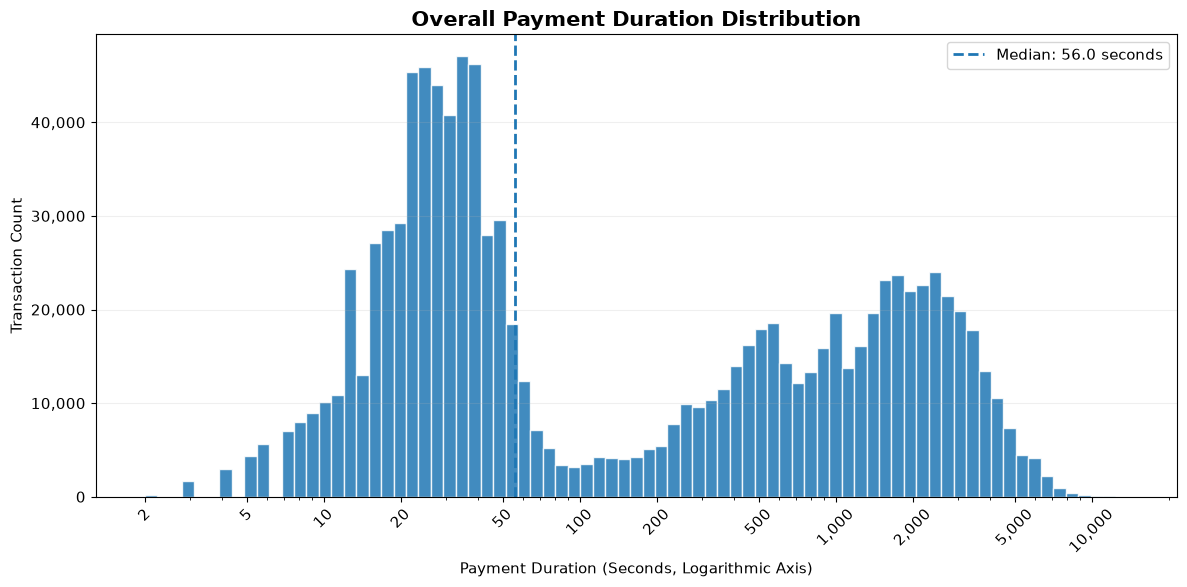


GLOBAL DURATION ANALYSIS COMPLETED
Total transactions: 1,048,575
Median duration: 56.0 seconds
Mean duration: 772.42 seconds

Duration unit: Seconds
Axis spacing: Logarithmic
Original transaction values: Unchanged

Global duration analysis completed successfully.


: 

In [ ]:
# ============================================================
# CELL 4 - GLOBAL PAYMENT DURATION ANALYSIS
# Purpose:
# Analyze overall payment duration, calculate descriptive
# statistics, investigate slow-payment thresholds, and
# visualize the duration distribution.
#
# Unit: Seconds
# Data Protection:
# - No transaction records are removed.
# - Original duration values remain unchanged.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


# ------------------------------------------------------------
# 1. Prepare duration values
# ------------------------------------------------------------

duration_values = (
    duration_df["DURATION"]
    .to_numpy(dtype=np.float64)
)

assert len(duration_values) == EXPECTED_RECORDS, (
    "Duration record count does not match the expected value."
)

assert np.isfinite(duration_values).all(), (
    "Invalid duration values detected."
)

assert (duration_values >= 0).all(), (
    "Negative duration values detected."
)


# ------------------------------------------------------------
# 2. Calculate global duration statistics
# ------------------------------------------------------------

global_stats = {
    "TRANSACTIONS": int(len(duration_values)),
    "MEAN_DURATION": float(np.mean(duration_values)),
    "MEDIAN_DURATION": float(np.median(duration_values)),
    "STD_DURATION": float(
        np.std(duration_values, ddof=1)
    ),
    "MIN_DURATION": float(np.min(duration_values)),
    "P25_DURATION": float(
        np.percentile(duration_values, 25)
    ),
    "P75_DURATION": float(
        np.percentile(duration_values, 75)
    ),
    "P90_DURATION": float(
        np.percentile(duration_values, 90)
    ),
    "P95_DURATION": float(
        np.percentile(duration_values, 95)
    ),
    "P99_DURATION": float(
        np.percentile(duration_values, 99)
    ),
    "MAX_DURATION": float(np.max(duration_values))
}

global_duration_table = pd.DataFrame([
    {
        "METRIC": metric,
        "VALUE": value,
        "UNIT": (
            "Transactions"
            if metric == "TRANSACTIONS"
            else "Seconds"
        )
    }
    for metric, value in global_stats.items()
])

export_table(
    global_duration_table,
    "duration_global_statistics.csv"
)


# ------------------------------------------------------------
# 3. Calculate slow-payment threshold statistics
# ------------------------------------------------------------

slow_thresholds = {
    "ABOVE_60_SECONDS": 60,
    "ABOVE_300_SECONDS": 300,
    "ABOVE_900_SECONDS": 900,
    "ABOVE_1800_SECONDS": 1800
}

tail_rows = []

for label, threshold in slow_thresholds.items():

    slow_count = int(
        (duration_values > threshold).sum()
    )

    slow_percentage = (
        slow_count / len(duration_values) * 100
    )

    tail_rows.append({
        "THRESHOLD": label,
        "THRESHOLD_SECONDS": threshold,
        "TRANSACTION_COUNT": slow_count,
        "PERCENT_OF_ALL": slow_percentage
    })

tail_summary = pd.DataFrame(tail_rows)

export_table(
    tail_summary,
    "duration_tail_thresholds.csv"
)


# ------------------------------------------------------------
# 4. Display global statistical results
# ------------------------------------------------------------

print("=" * 65)
print("GLOBAL PAYMENT DURATION STATISTICS")
print("=" * 65)

display(global_duration_table)

print("\nSlow Payment Threshold Statistics:")
display(tail_summary)


# ------------------------------------------------------------
# 5. Prepare positive duration values for log visualization
# ------------------------------------------------------------

positive_durations = duration_values[
    duration_values > 0
]

assert len(positive_durations) > 0, (
    "No positive duration values available."
)


# ------------------------------------------------------------
# 6. Create logarithmic histogram bins
# ------------------------------------------------------------

bins = np.geomspace(
    positive_durations.min(),
    positive_durations.max(),
    80
)


# ------------------------------------------------------------
# 7. Create payment duration histogram
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    positive_durations,
    bins=bins,
    edgecolor="white",
    alpha=0.85
)


# ------------------------------------------------------------
# 8. Configure readable axis labels in seconds
# ------------------------------------------------------------

ax.set_xscale("log")

tick_values = [
    2, 5, 10, 20, 50, 100,
    200, 500, 1000, 2000,
    5000, 10000
]

visible_ticks = [
    value
    for value in tick_values
    if positive_durations.min()
    <= value
    <= positive_durations.max()
]

ax.set_xticks(visible_ticks)

ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(
        lambda value, position: f"{value:,.0f}"
    )
)

ax.xaxis.set_minor_formatter(
    mtick.NullFormatter()
)

ax.tick_params(
    axis="x",
    labelrotation=45
)

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)


# ------------------------------------------------------------
# 9. Add median duration reference line
# ------------------------------------------------------------

median_duration = global_stats["MEDIAN_DURATION"]

ax.axvline(
    median_duration,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_duration:,.1f} seconds"
)


# ------------------------------------------------------------
# 10. Configure chart presentation
# ------------------------------------------------------------

ax.set_title(
    "Overall Payment Duration Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Payment Duration (Seconds, Logarithmic Axis)"
)

ax.set_ylabel(
    "Transaction Count"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()


# ------------------------------------------------------------
# 11. Export the chart
# ------------------------------------------------------------

export_chart(
    "duration_global_distribution.png"
)

plt.show()


# ------------------------------------------------------------
# 12. Final validation
# ------------------------------------------------------------

assert global_stats["TRANSACTIONS"] == EXPECTED_RECORDS

assert (
    global_stats["MIN_DURATION"]
    <= global_stats["MEDIAN_DURATION"]
    <= global_stats["MAX_DURATION"]
)

print("\n" + "=" * 65)
print("GLOBAL DURATION ANALYSIS COMPLETED")
print("=" * 65)

print(
    "Total transactions:",
    f"{global_stats['TRANSACTIONS']:,}"
)

print(
    "Median duration:",
    f"{global_stats['MEDIAN_DURATION']:,.1f} seconds"
)

print(
    "Mean duration:",
    f"{global_stats['MEAN_DURATION']:,.2f} seconds"
)

print("\nDuration unit: Seconds")
print("Axis spacing: Logarithmic")
print("Original transaction values: Unchanged")

print("\nGlobal duration analysis completed successfully.")

Chart exported: duration_short_range.png


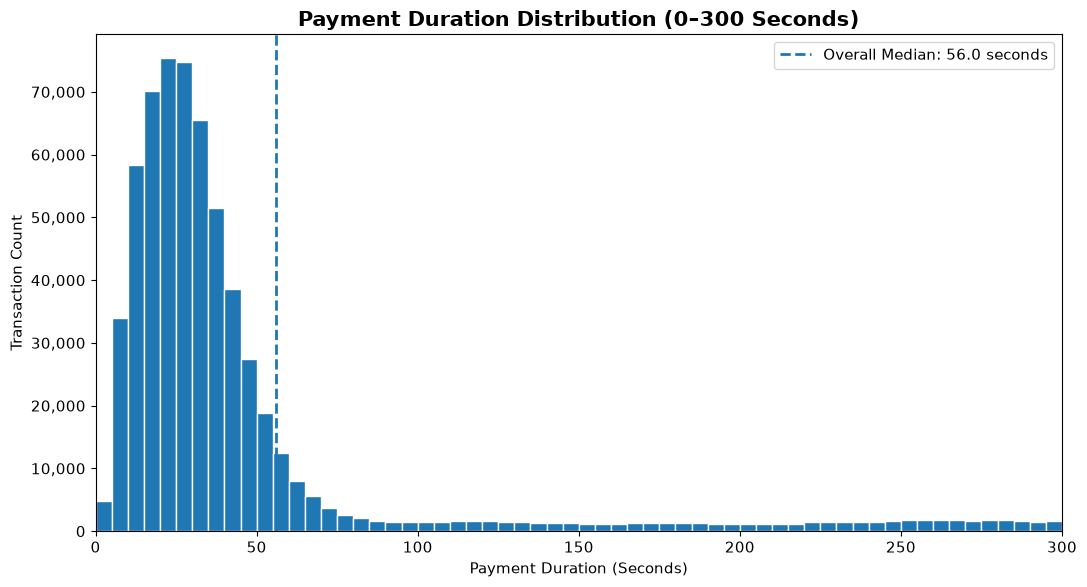

In [6]:
# ============================================================
# OPTIONAL - LINEAR DURATION HISTOGRAM (0 TO 300 SECONDS)
# Purpose:
# Show short payment durations using a conventional axis.
# ============================================================

short_durations = duration_df.loc[
    duration_df["DURATION"].between(0, 300),
    "DURATION"
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    short_durations,
    bins=np.arange(0, 305, 5),
    edgecolor="white"
)

ax.axvline(
    global_stats["MEDIAN_DURATION"],
    linestyle="--",
    linewidth=2,
    label=(
        f"Overall Median: "
        f"{global_stats['MEDIAN_DURATION']:.1f} seconds"
    )
)

ax.set_title(
    "Payment Duration Distribution (0–300 Seconds)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Payment Duration (Seconds)")
ax.set_ylabel("Transaction Count")

ax.set_xlim(0, 300)

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.legend()

plt.tight_layout()

export_chart(
    "duration_short_range.png"
)

plt.show()

Table exported: duration_by_routing_type.csv


,ROUTING_TYPE,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION,MEDIAN_VS_DIRECT_RATIO,MEDIAN_VS_DIRECT_DIFFERENCE
1,DIRECT,662245,663.384293,39.0,2344.0,3146.0,4833.0,1.000000,0.0
2,INDIRECT,342752,964.706975,283.0,2927.0,3815.0,5789.0,7.256410,244.0
0,COVERED,43578,916.991395,378.0,2801.0,3774.0,5851.0,9.692308,339.0


Chart exported: duration_median_by_routing.png


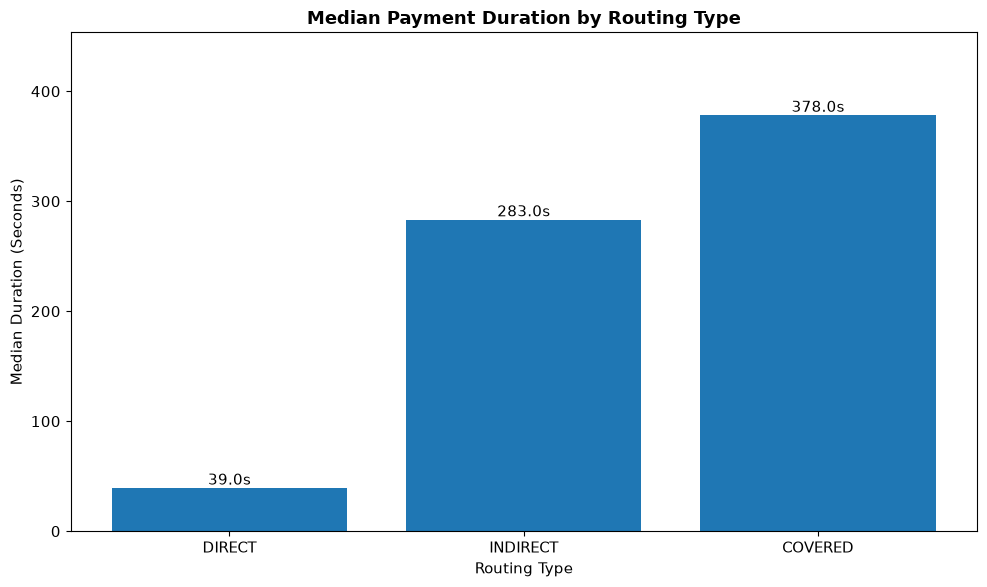

Routing duration comparison completed.


In [7]:
# ============================================================
# CELL 5 - PAYMENT DURATION BY ROUTING TYPE
# Purpose:
# Compare duration distributions across Direct, Indirect,
# and Covered routes.
# ============================================================

route_duration = summarize_duration(
    duration_df,
    ["ROUTING_TYPE"]
)

route_duration = route_duration.sort_values(
    "MEDIAN_DURATION"
)

# ------------------------------------------------------------
# 1. Compare with Direct baseline
# ------------------------------------------------------------

direct_row = route_duration.loc[
    route_duration["ROUTING_TYPE"] == "DIRECT"
]

assert len(direct_row) == 1

direct_median = float(
    direct_row["MEDIAN_DURATION"].iloc[0]
)

route_duration["MEDIAN_VS_DIRECT_RATIO"] = (
    route_duration["MEDIAN_DURATION"] / direct_median
)

route_duration["MEDIAN_VS_DIRECT_DIFFERENCE"] = (
    route_duration["MEDIAN_DURATION"] - direct_median
)

export_table(
    route_duration,
    "duration_by_routing_type.csv"
)

display(route_duration)

# ------------------------------------------------------------
# 2. Create median comparison chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    route_duration["ROUTING_TYPE"].astype(str),
    route_duration["MEDIAN_DURATION"]
)

ax.set_title(
    "Median Payment Duration by Routing Type",
    fontweight="bold"
)

ax.set_xlabel("Routing Type")
ax.set_ylabel("Median Duration (Seconds)")

ax.set_ylim(
    0,
    route_duration["MEDIAN_DURATION"].max() * 1.2
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

export_chart("duration_median_by_routing.png")

plt.show()

print("Routing duration comparison completed.")

Table exported: duration_by_routing_and_participants.csv


,ROUTING_TYPE,PARTICIPANTS,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION,SAMPLE_STATUS
0,COVERED,3,27628,807.410236,282.0,2483.3,3490.65,5658.65,ADEQUATE_FOR_EXPLORATION
1,COVERED,4,10091,984.380141,435.0,2902.0,3807.50,5850.10,ADEQUATE_FOR_EXPLORATION
2,COVERED,5,3733,1207.560675,583.0,3296.8,4488.60,6394.48,ADEQUATE_FOR_EXPLORATION
3,COVERED,6,1340,1402.740299,735.0,3691.6,4742.10,6690.10,ADEQUATE_FOR_EXPLORATION
4,COVERED,7,482,1547.205394,901.5,3890.3,4886.15,7058.61,ADEQUATE_FOR_EXPLORATION
5,COVERED,8,186,1843.768817,1258.5,4521.0,5214.25,7306.85,ADEQUATE_FOR_EXPLORATION
6,COVERED,9,75,1916.360000,1478.0,4164.6,4894.90,8247.58,SMALL_SAMPLE
7,COVERED,10,29,2344.310345,1945.0,4953.6,5526.80,6046.00,SMALL_SAMPLE
8,COVERED,11,10,2520.100000,1491.0,5040.2,7934.60,10250.12,SMALL_SAMPLE
9,COVERED,12,3,2136.666667,666.0,4653.2,5151.60,5550.32,SMALL_SAMPLE


Chart exported: duration_routing_participant.png


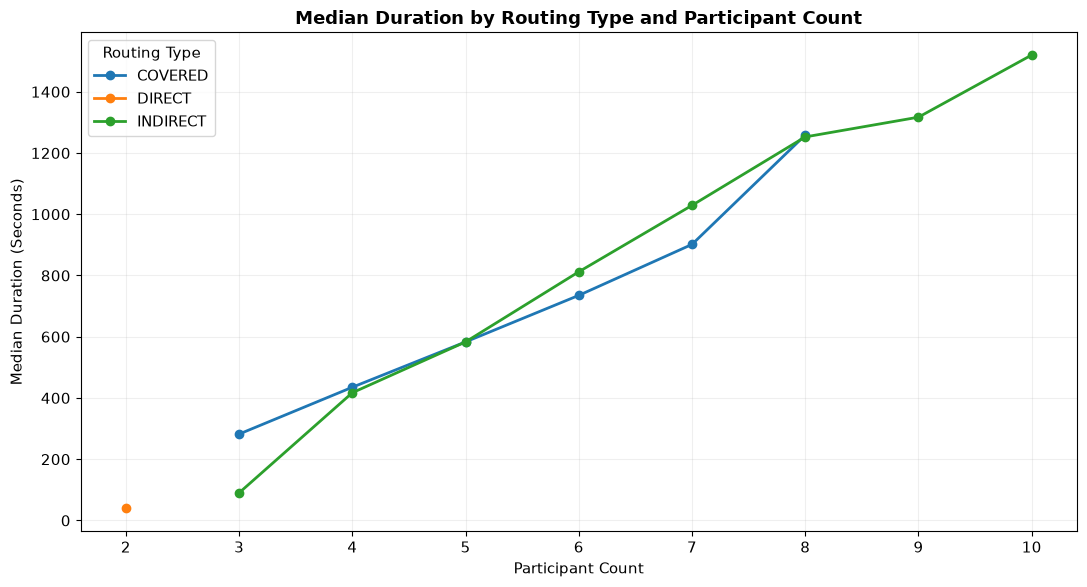

Participant-adjusted routing exploration completed.


In [8]:
# ============================================================
# CELL 6 - PARTICIPANT COUNT AND ROUTING TYPE
# Purpose:
# Compare duration across participant counts within
# each routing category.
# ============================================================

participant_route_duration = summarize_duration(
    duration_df,
    ["ROUTING_TYPE", "PARTICIPANTS"]
)

participant_route_duration["SAMPLE_STATUS"] = np.where(
    participant_route_duration["TRANSACTION_COUNT"]
    >= MIN_GROUP_SIZE,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

participant_route_duration = (
    participant_route_duration.sort_values(
        ["ROUTING_TYPE", "PARTICIPANTS"]
    )
)

export_table(
    participant_route_duration,
    "duration_by_routing_and_participants.csv"
)

display(participant_route_duration)

# ------------------------------------------------------------
# 1. Focus on groups with sufficient sample sizes
# ------------------------------------------------------------

plot_data = participant_route_duration.loc[
    (participant_route_duration["TRANSACTION_COUNT"]
     >= MIN_GROUP_SIZE)
    &
    (participant_route_duration["PARTICIPANTS"] <= 10)
].copy()

fig, ax = plt.subplots(figsize=(11, 6))

for route, group in plot_data.groupby(
    "ROUTING_TYPE",
    observed=True
):

    group = group.sort_values("PARTICIPANTS")

    ax.plot(
        group["PARTICIPANTS"],
        group["MEDIAN_DURATION"],
        marker="o",
        linewidth=2,
        label=str(route)
    )

ax.set_title(
    "Median Duration by Routing Type and Participant Count",
    fontweight="bold"
)

ax.set_xlabel("Participant Count")
ax.set_ylabel("Median Duration (Seconds)")

ax.grid(alpha=0.2)
ax.legend(title="Routing Type")

plt.tight_layout()

export_chart("duration_routing_participant.png")

plt.show()

print("Participant-adjusted routing exploration completed.")

In [9]:
# ============================================================
# CELL 7 - CONDITIONAL FX DURATION ANALYSIS
# Purpose:
# Investigate FX-duration relationships within matched
# routing type and participant count groups.
# ============================================================

fx_duration = summarize_duration(
    duration_df,
    ["ROUTING_TYPE", "PARTICIPANTS", "FX_COUNT"]
)

fx_duration["SAMPLE_STATUS"] = np.where(
    fx_duration["TRANSACTION_COUNT"] >= MIN_GROUP_SIZE,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

fx_duration = fx_duration.sort_values(
    ["ROUTING_TYPE", "PARTICIPANTS", "FX_COUNT"]
)

export_table(
    fx_duration,
    "duration_by_routing_participants_fx.csv"
)

# ------------------------------------------------------------
# 1. Compare adjacent FX counts within matching groups
# ------------------------------------------------------------

comparison_rows = []

for (route, participants), group in fx_duration.groupby(
    ["ROUTING_TYPE", "PARTICIPANTS"],
    observed=True
):

    group = group.sort_values("FX_COUNT")

    records = {
        int(row.FX_COUNT): row
        for row in group.itertuples(index=False)
    }

    for fx_value, current in records.items():

        next_fx = fx_value + 1

        if next_fx not in records:
            continue

        following = records[next_fx]

        comparison_rows.append({
            "ROUTING_TYPE": str(route),
            "PARTICIPANTS": participants,
            "BASE_FX": fx_value,
            "NEXT_FX": next_fx,
            "BASE_COUNT": current.TRANSACTION_COUNT,
            "NEXT_COUNT": following.TRANSACTION_COUNT,
            "BASE_MEDIAN": current.MEDIAN_DURATION,
            "NEXT_MEDIAN": following.MEDIAN_DURATION,
            "MEDIAN_DIFFERENCE": (
                following.MEDIAN_DURATION
                - current.MEDIAN_DURATION
            ),
            "MEDIAN_RATIO": safe_ratio(
                following.MEDIAN_DURATION,
                current.MEDIAN_DURATION
            )
        })

fx_adjacent_comparison = pd.DataFrame(comparison_rows)

fx_adjacent_comparison["RELIABLE_COMPARISON"] = (
    (fx_adjacent_comparison["BASE_COUNT"] >= MIN_GROUP_SIZE)
    &
    (fx_adjacent_comparison["NEXT_COUNT"] >= MIN_GROUP_SIZE)
)

export_table(
    fx_adjacent_comparison,
    "fx_adjacent_duration_comparisons.csv"
)

print("Conditional FX duration statistics:")
display(fx_duration.head(40))

print("\nAdjacent FX comparisons with sufficient samples:")
display(
    fx_adjacent_comparison.loc[
        fx_adjacent_comparison["RELIABLE_COMPARISON"]
    ].head(40)
)

print("Conditional FX investigation completed.")

Table exported: duration_by_routing_participants_fx.csv
Table exported: fx_adjacent_duration_comparisons.csv
Conditional FX duration statistics:


,ROUTING_TYPE,PARTICIPANTS,FX_COUNT,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION,SAMPLE_STATUS
0,COVERED,3,0,1384,827.398844,332.0,2385.0,3354.40,6017.70,ADEQUATE_FOR_EXPLORATION
1,COVERED,3,1,5540,697.436101,298.0,2016.6,3014.35,5050.22,ADEQUATE_FOR_EXPLORATION
2,COVERED,3,2,20704,835.501063,275.0,2576.0,3598.40,5830.00,ADEQUATE_FOR_EXPLORATION
3,COVERED,4,0,130,1086.130769,514.5,2922.4,3508.60,5640.38,ADEQUATE_FOR_EXPLORATION
4,COVERED,4,1,616,858.621753,438.0,2604.5,3292.50,5186.25,ADEQUATE_FOR_EXPLORATION
5,COVERED,4,2,3100,936.390000,425.5,2752.0,3679.85,5872.19,ADEQUATE_FOR_EXPLORATION
6,COVERED,4,3,6245,1018.488871,439.0,2989.0,3944.80,5859.68,ADEQUATE_FOR_EXPLORATION
7,COVERED,5,0,19,2156.578947,1891.0,3570.6,4269.60,8017.92,SMALL_SAMPLE
8,COVERED,5,1,67,1073.985075,594.0,2401.6,4570.40,6047.90,SMALL_SAMPLE
9,COVERED,5,2,419,1062.350835,556.0,2826.4,4250.80,5871.60,ADEQUATE_FOR_EXPLORATION



Adjacent FX comparisons with sufficient samples:


,ROUTING_TYPE,PARTICIPANTS,BASE_FX,NEXT_FX,BASE_COUNT,NEXT_COUNT,BASE_MEDIAN,NEXT_MEDIAN,MEDIAN_DIFFERENCE,MEDIAN_RATIO,RELIABLE_COMPARISON
0,COVERED,3,0,1,1384,5540,332.0,298.0,-34.0,0.897590,True
1,COVERED,3,1,2,5540,20704,298.0,275.0,-23.0,0.922819,True
2,COVERED,4,0,1,130,616,514.5,438.0,-76.5,0.851312,True
3,COVERED,4,1,2,616,3100,438.0,425.5,-12.5,0.971461,True
4,COVERED,4,2,3,3100,6245,425.5,439.0,13.5,1.031727,True
7,COVERED,5,2,3,419,1198,556.0,611.0,55.0,1.098921,True
8,COVERED,5,3,4,1198,2030,611.0,572.0,-39.0,0.936170,True
12,COVERED,6,3,4,184,493,707.0,702.0,-5.0,0.992928,True
13,COVERED,6,4,5,493,606,702.0,802.5,100.5,1.143162,True
17,COVERED,7,5,6,163,192,1129.0,767.5,-361.5,0.679805,True


Conditional FX investigation completed.


In [10]:
# ============================================================
# CELL 8 - MATCHED INDIRECT VS COVERED DURATION
# Purpose:
# Compare non-direct routing categories within matching
# participant, FX, currency, and party segments.
# ============================================================

matched_data = duration_df.loc[
    duration_df["ROUTING_TYPE"].isin(
        ["INDIRECT", "COVERED"]
    ),
    [
        "ROUTING_TYPE",
        "PARTICIPANTS",
        "FX_COUNT",
        "CURRENCY",
        "PARTY_PAIR",
        "DURATION"
    ]
].copy()

matched_data["LOG_DURATION"] = np.log1p(
    matched_data["DURATION"]
)

strata_columns = [
    "PARTICIPANTS",
    "FX_COUNT",
    "CURRENCY",
    "PARTY_PAIR"
]

# ------------------------------------------------------------
# 1. Aggregate duration within each comparable stratum
# ------------------------------------------------------------

strata_summary = (
    matched_data.groupby(
        strata_columns + ["ROUTING_TYPE"],
        observed=True
    )
    .agg(
        COUNT=("DURATION", "size"),
        MEAN_LOG_DURATION=("LOG_DURATION", "mean"),
        MEDIAN_DURATION=("DURATION", "median")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. Prepare matched routing values
# ------------------------------------------------------------

matched_pivot = strata_summary.pivot(
    index=strata_columns,
    columns="ROUTING_TYPE",
    values=[
        "COUNT",
        "MEAN_LOG_DURATION",
        "MEDIAN_DURATION"
    ]
)

matched_pivot.columns = [
    f"{metric}_{route}"
    for metric, route in matched_pivot.columns
]

matched_pivot = matched_pivot.reset_index()

required_matched_columns = [
    "COUNT_INDIRECT",
    "COUNT_COVERED",
    "MEAN_LOG_DURATION_INDIRECT",
    "MEAN_LOG_DURATION_COVERED"
]

for col in required_matched_columns:
    assert col in matched_pivot.columns

# ------------------------------------------------------------
# 3. Retain strata represented by both routing categories
# ------------------------------------------------------------

matched_pivot = matched_pivot.dropna(
    subset=required_matched_columns
).copy()

matched_pivot["LOG_DURATION_DIFFERENCE"] = (
    matched_pivot["MEAN_LOG_DURATION_COVERED"]
    - matched_pivot["MEAN_LOG_DURATION_INDIRECT"]
)

matched_pivot["MATCH_WEIGHT"] = np.minimum(
    matched_pivot["COUNT_INDIRECT"],
    matched_pivot["COUNT_COVERED"]
)

matched_pivot["RELATIVE_DIFFERENCE_PERCENT"] = (
    np.expm1(
        matched_pivot["LOG_DURATION_DIFFERENCE"]
    ) * 100
)

# ------------------------------------------------------------
# 4. Calculate an overall matched comparison
# ------------------------------------------------------------

total_match_weight = matched_pivot["MATCH_WEIGHT"].sum()

assert total_match_weight > 0, (
    "No comparable Indirect and Covered strata were found."
)

weighted_log_difference = np.average(
    matched_pivot["LOG_DURATION_DIFFERENCE"],
    weights=matched_pivot["MATCH_WEIGHT"]
)

overall_relative_difference = (
    np.expm1(weighted_log_difference) * 100
)

matched_summary = pd.DataFrame([{
    "MATCHED_STRATA": len(matched_pivot),
    "MATCH_WEIGHT_TOTAL": total_match_weight,
    "WEIGHTED_LOG_DIFFERENCE": weighted_log_difference,
    "RELATIVE_DIFFERENCE_PERCENT": overall_relative_difference
}])

# ------------------------------------------------------------
# 5. Export results
# ------------------------------------------------------------

export_table(
    matched_pivot,
    "indirect_covered_duration_matched_strata.csv"
)

export_table(
    matched_summary,
    "indirect_covered_duration_matched_summary.csv"
)

print("Matched comparison summary:")
display(matched_summary)

print("\nLargest well-supported matched strata:")
display(
    matched_pivot.sort_values(
        "MATCH_WEIGHT",
        ascending=False
    ).head(20)
)

print("Matched Indirect/Covered duration analysis completed.")

Table exported: indirect_covered_duration_matched_strata.csv
Table exported: indirect_covered_duration_matched_summary.csv
Matched comparison summary:


,MATCHED_STRATA,MATCH_WEIGHT_TOTAL,WEIGHTED_LOG_DIFFERENCE,RELATIVE_DIFFERENCE_PERCENT
0,1777,43393.0,0.113609,12.03143



Largest well-supported matched strata:


,PARTICIPANTS,FX_COUNT,CURRENCY,PARTY_PAIR,COUNT_COVERED,COUNT_INDIRECT,MEAN_LOG_DURATION_COVERED,MEAN_LOG_DURATION_INDIRECT,MEDIAN_DURATION_COVERED,MEDIAN_DURATION_INDIRECT,LOG_DURATION_DIFFERENCE,MATCH_WEIGHT,RELATIVE_DIFFERENCE_PERCENT
547,3,2,EUR,B_C,3633.0,25314.0,5.371596,5.272694,280.0,123.0,0.098902,3633.0,10.395843
602,3,2,USD,B_C,1818.0,14943.0,5.159827,5.106968,154.0,61.0,0.052859,1818.0,5.428096
551,3,2,GBP,B_C,1674.0,7486.0,5.425946,5.278082,298.5,115.0,0.147864,1674.0,15.935495
535,3,2,CHF,B_C,1565.0,6551.0,5.167667,5.033624,216.0,56.0,0.134043,1565.0,14.344215
546,3,2,EUR,B_B,1533.0,10254.0,5.323982,5.242897,269.0,120.5,0.081086,1533.0,8.446385
78,3,1,EUR,B_C,1368.0,10473.0,5.399870,5.266711,321.5,147.0,0.133159,1368.0,14.243163
1833,4,3,EUR,B_C,1128.0,8127.0,5.837825,5.739143,450.5,431.0,0.098682,1128.0,10.371507
549,3,2,EUR,C_C,982.0,6935.0,5.412162,5.345422,304.0,218.0,0.066740,982.0,6.901784
601,3,2,USD,B_B,779.0,6330.0,5.309851,5.120642,260.0,61.0,0.189209,779.0,20.829382
1402,4,2,EUR,B_C,692.0,4869.0,5.714767,5.739851,403.0,431.0,-0.025085,692.0,-2.477251


Matched Indirect/Covered duration analysis completed.


In [11]:
# ============================================================
# CELL 9 - ROUTING GAP AND PAYMENT DURATION
# Purpose:
# Compare duration by path observability within routing,
# participant count, and FX count groups.
# ============================================================

gap_duration = summarize_duration(
    duration_df,
    [
        "ROUTING_TYPE",
        "PARTICIPANTS",
        "FX_COUNT",
        "PATH_GAP"
    ]
)

export_table(
    gap_duration,
    "duration_by_routing_participants_fx_gap.csv"
)

# ------------------------------------------------------------
# 1. Create comparable gap/non-gap strata
# ------------------------------------------------------------

gap_pivot = gap_duration.pivot(
    index=[
        "ROUTING_TYPE",
        "PARTICIPANTS",
        "FX_COUNT"
    ],
    columns="PATH_GAP",
    values=[
        "TRANSACTION_COUNT",
        "MEDIAN_DURATION"
    ]
)

gap_pivot.columns = [
    f"{metric}_{gap}"
    for metric, gap in gap_pivot.columns
]

gap_pivot = gap_pivot.reset_index()

required_gap_columns = [
    "TRANSACTION_COUNT_Y",
    "TRANSACTION_COUNT_N",
    "MEDIAN_DURATION_Y",
    "MEDIAN_DURATION_N"
]

for col in required_gap_columns:
    assert col in gap_pivot.columns

gap_pivot = gap_pivot.dropna(
    subset=required_gap_columns
).copy()

# ------------------------------------------------------------
# 2. Compare medians within matched groups
# ------------------------------------------------------------

gap_pivot["MEDIAN_DIFFERENCE"] = (
    gap_pivot["MEDIAN_DURATION_Y"]
    - gap_pivot["MEDIAN_DURATION_N"]
)

gap_pivot["MEDIAN_RATIO"] = (
    gap_pivot["MEDIAN_DURATION_Y"]
    / gap_pivot["MEDIAN_DURATION_N"]
)

gap_pivot["SAMPLE_STATUS"] = np.where(
    (
        gap_pivot["TRANSACTION_COUNT_Y"] >= MIN_GROUP_SIZE
    )
    &
    (
        gap_pivot["TRANSACTION_COUNT_N"] >= MIN_GROUP_SIZE
    ),
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

export_table(
    gap_pivot,
    "gap_duration_matched_comparison.csv"
)

display(
    gap_pivot.loc[
        gap_pivot["SAMPLE_STATUS"]
        == "ADEQUATE_FOR_EXPLORATION"
    ].head(40)
)

print("Routing gap duration comparison completed.")

Table exported: duration_by_routing_participants_fx_gap.csv
Table exported: gap_duration_matched_comparison.csv


,ROUTING_TYPE,PARTICIPANTS,FX_COUNT,TRANSACTION_COUNT_N,TRANSACTION_COUNT_Y,MEDIAN_DURATION_N,MEDIAN_DURATION_Y,MEDIAN_DIFFERENCE,MEDIAN_RATIO,SAMPLE_STATUS
0,COVERED,3,0,1231.0,153.0,336.0,275.0,-61.0,0.818452,ADEQUATE_FOR_EXPLORATION
1,COVERED,3,1,4974.0,566.0,297.0,319.5,22.5,1.075758,ADEQUATE_FOR_EXPLORATION
2,COVERED,3,2,18856.0,1848.0,277.0,240.5,-36.5,0.868231,ADEQUATE_FOR_EXPLORATION
5,COVERED,4,2,2651.0,449.0,440.0,343.0,-97.0,0.779545,ADEQUATE_FOR_EXPLORATION
6,COVERED,4,3,5349.0,896.0,440.0,433.5,-6.5,0.985227,ADEQUATE_FOR_EXPLORATION
10,COVERED,5,3,956.0,242.0,633.0,529.0,-104.0,0.835703,ADEQUATE_FOR_EXPLORATION
11,COVERED,5,4,1644.0,386.0,583.5,531.5,-52.0,0.910883,ADEQUATE_FOR_EXPLORATION
17,COVERED,6,5,467.0,139.0,751.0,1013.0,262.0,1.348868,ADEQUATE_FOR_EXPLORATION
47,DIRECT,2,0,98889.0,5085.0,45.0,45.0,0.0,1.000000,ADEQUATE_FOR_EXPLORATION
48,DIRECT,2,1,530315.0,27956.0,39.0,38.0,-1.0,0.974359,ADEQUATE_FOR_EXPLORATION


Routing gap duration comparison completed.


In [12]:
# ============================================================
# CELL 10 - SLOW PAYMENT INVESTIGATION
# Purpose:
# Identify slow-payment concentration across routing
# types and participant counts.
# ============================================================

SLOW_THRESHOLDS = [300, 900, 1800]

slow_records = []

group_columns = [
    "ROUTING_TYPE",
    "PARTICIPANTS"
]

for threshold in SLOW_THRESHOLDS:

    temp = (
        duration_df.groupby(
            group_columns,
            observed=True
        )["DURATION"]
        .agg(
            TOTAL="size",
            SLOW_COUNT=lambda x: int(
                (x > threshold).sum()
            )
        )
        .reset_index()
    )

    temp["THRESHOLD_SECONDS"] = threshold

    temp["SLOW_RATE_PERCENT"] = (
        temp["SLOW_COUNT"] / temp["TOTAL"] * 100
    )

    slow_records.append(temp)

slow_payment_table = pd.concat(
    slow_records,
    ignore_index=True
)

slow_payment_table["SAMPLE_STATUS"] = np.where(
    slow_payment_table["TOTAL"] >= MIN_GROUP_SIZE,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

export_table(
    slow_payment_table,
    "slow_payment_rates_by_route_participants.csv"
)

print("Slow payment rates:")
display(
    slow_payment_table.loc[
        slow_payment_table["SAMPLE_STATUS"]
        == "ADEQUATE_FOR_EXPLORATION"
    ].head(40)
)

# ------------------------------------------------------------
# 1. Compare slow-payment rates by routing type
# ------------------------------------------------------------

route_slow = []

for threshold in SLOW_THRESHOLDS:

    grouped = (
        duration_df.groupby(
            "ROUTING_TYPE",
            observed=True
        )["DURATION"]
        .agg(
            TOTAL="size",
            SLOW_COUNT=lambda x: int(
                (x > threshold).sum()
            )
        )
        .reset_index()
    )

    grouped["THRESHOLD_SECONDS"] = threshold

    grouped["SLOW_RATE_PERCENT"] = (
        grouped["SLOW_COUNT"]
        / grouped["TOTAL"] * 100
    )

    route_slow.append(grouped)

route_slow_table = pd.concat(
    route_slow,
    ignore_index=True
)

export_table(
    route_slow_table,
    "slow_payment_rates_by_routing.csv"
)

display(route_slow_table)

print("Slow payment analysis completed.")

Table exported: slow_payment_rates_by_route_participants.csv
Slow payment rates:


,ROUTING_TYPE,PARTICIPANTS,TOTAL,SLOW_COUNT,THRESHOLD_SECONDS,SLOW_RATE_PERCENT,SAMPLE_STATUS
0,COVERED,3,27628,13552,300,49.051687,ADEQUATE_FOR_EXPLORATION
1,COVERED,4,10091,5775,300,57.229214,ADEQUATE_FOR_EXPLORATION
2,COVERED,5,3733,2465,300,66.032681,ADEQUATE_FOR_EXPLORATION
3,COVERED,6,1340,968,300,72.238806,ADEQUATE_FOR_EXPLORATION
4,COVERED,7,482,374,300,77.593361,ADEQUATE_FOR_EXPLORATION
5,COVERED,8,186,162,300,87.096774,ADEQUATE_FOR_EXPLORATION
11,DIRECT,2,662245,240752,300,36.353917,ADEQUATE_FOR_EXPLORATION
12,INDIRECT,3,216358,95839,300,44.296490,ADEQUATE_FOR_EXPLORATION
13,INDIRECT,4,79612,42968,300,53.971763,ADEQUATE_FOR_EXPLORATION
14,INDIRECT,5,29497,18157,300,61.555412,ADEQUATE_FOR_EXPLORATION


Table exported: slow_payment_rates_by_routing.csv


,ROUTING_TYPE,TOTAL,SLOW_COUNT,THRESHOLD_SECONDS,SLOW_RATE_PERCENT
0,COVERED,43578,23399,300,53.694525
1,DIRECT,662245,240752,300,36.353917
2,INDIRECT,342752,169387,300,49.419697
3,COVERED,43578,13117,900,30.100050
4,DIRECT,662245,163981,900,24.761380
5,INDIRECT,342752,117326,900,34.230581
6,COVERED,43578,8091,1800,18.566708
7,DIRECT,662245,95678,1800,14.447523
8,INDIRECT,342752,73043,1800,21.310744


Slow payment analysis completed.


Table exported: direct_duration_by_fx.csv


,FX_COUNT,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION
0,0,103974,702.368977,45.0,2406.7,3239.0,5129.54
1,1,558271,656.123673,39.0,2323.0,3134.0,4795.00


Table exported: direct_duration_regime_summary.csv


,DURATION_BAND,FX_COUNT,TRANSACTION_COUNT,MEDIAN_AMOUNT,MEDIAN_DURATION
0,0-60s,0,55895,5519.000,24.0
1,0-60s,1,325753,3597.510,24.0
2,60-300s,0,6962,5799.405,188.0
3,60-300s,1,32883,3740.900,178.0
4,300-900s,0,14870,5418.220,507.0
5,300-900s,1,61901,3503.130,537.0
6,900s+,0,26247,4606.850,2139.0
7,900s+,1,137734,2817.000,2006.0


Table exported: direct_duration_by_currency.csv
Major currency duration profiles:


,CURRENCY,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION
17,EUR,208696,671.124875,41.0,2355.0,3155.00,4864.05
44,USD,111658,611.678617,37.0,2218.3,3076.00,4512.00
18,GBP,57913,662.200180,43.0,2319.0,3156.00,4922.88
11,CHF,53361,510.423943,38.0,1829.0,2835.00,4753.00
40,SGD,24340,582.688209,34.0,2151.0,3283.00,4495.00
13,CNY,21770,728.591318,62.0,2323.0,3243.00,4494.00
19,HKD,13225,694.486654,36.0,2245.6,2956.00,5053.12
23,JPY,12304,971.199529,46.0,3201.0,4520.00,6428.97
3,AUD,11410,619.987642,36.0,2501.0,4094.00,4626.82
10,CAD,7608,638.924159,29.0,2513.9,3071.95,5670.00


Chart exported: direct_duration_ecdf_by_fx.png


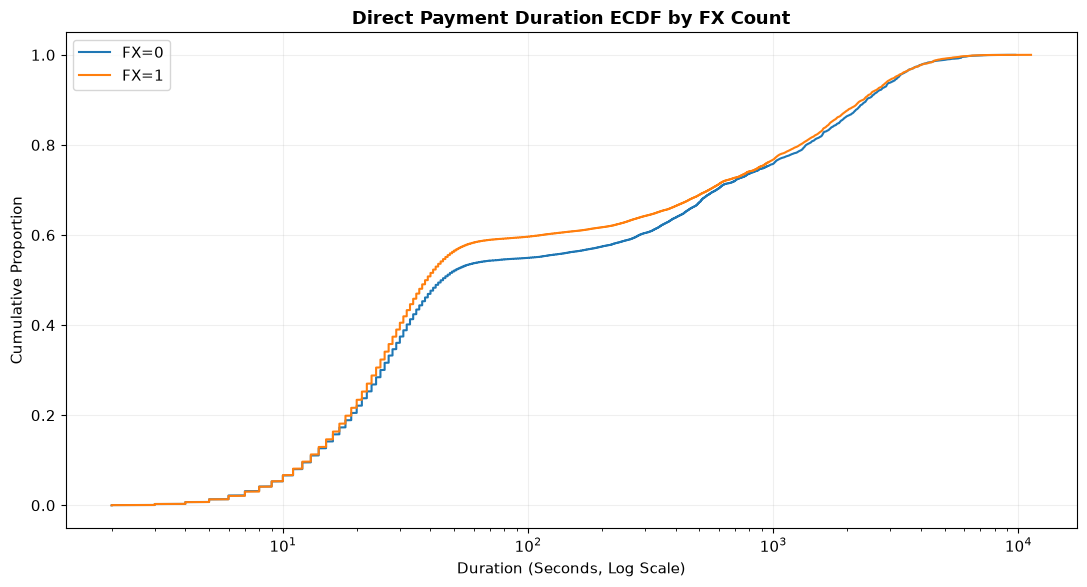

Direct payment regime investigation completed.


In [13]:
# ============================================================
# CELL 11 - DIRECT PAYMENT DURATION REGIMES
# Purpose:
# Investigate why some two-participant Direct payments
# still show long processing durations.
# ============================================================

direct_df = duration_df.loc[
    duration_df["ROUTING_TYPE"] == "DIRECT"
].copy()

assert len(direct_df) == 662_245

# ------------------------------------------------------------
# 1. Compare FX groups within Direct routing
# ------------------------------------------------------------

direct_fx_duration = summarize_duration(
    direct_df,
    ["FX_COUNT"]
)

export_table(
    direct_fx_duration,
    "direct_duration_by_fx.csv"
)

display(direct_fx_duration)

# ------------------------------------------------------------
# 2. Define exploratory duration bands
# ------------------------------------------------------------

duration_bins = [
    -np.inf,
    60,
    300,
    900,
    np.inf
]

duration_labels = [
    "0-60s",
    "60-300s",
    "300-900s",
    "900s+"
]

direct_df["DURATION_BAND"] = pd.cut(
    direct_df["DURATION"],
    bins=duration_bins,
    labels=duration_labels
)

direct_band_summary = (
    direct_df.groupby(
        ["DURATION_BAND", "FX_COUNT"],
        observed=True
    )
    .agg(
        TRANSACTION_COUNT=("DURATION", "size"),
        MEDIAN_AMOUNT=("AMOUNT", "median"),
        MEDIAN_DURATION=("DURATION", "median")
    )
    .reset_index()
)

export_table(
    direct_band_summary,
    "direct_duration_regime_summary.csv"
)

display(direct_band_summary)

# ------------------------------------------------------------
# 3. Compare direct-payment duration quantiles by currency
# ------------------------------------------------------------

currency_counts = (
    direct_df["CURRENCY"].value_counts()
)

major_currencies = currency_counts[
    currency_counts >= 1000
].index

direct_currency = summarize_duration(
    direct_df.loc[
        direct_df["CURRENCY"].isin(major_currencies)
    ],
    ["CURRENCY"]
)

direct_currency = direct_currency.sort_values(
    "TRANSACTION_COUNT",
    ascending=False
)

export_table(
    direct_currency,
    "direct_duration_by_currency.csv"
)

print("Major currency duration profiles:")
display(direct_currency.head(20))

# ------------------------------------------------------------
# 4. Compare log-duration distribution by FX count
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

for fx, group in direct_df.groupby(
    "FX_COUNT",
    observed=True
):

    values = group["DURATION"].to_numpy()

    if len(values) < 100:
        continue

    values = np.sort(values)

    cumulative = (
        np.arange(1, len(values) + 1) / len(values)
    )

    ax.plot(
        values,
        cumulative,
        label=f"FX={fx}"
    )

ax.set_xscale("log")

ax.set_title(
    "Direct Payment Duration ECDF by FX Count",
    fontweight="bold"
)

ax.set_xlabel("Duration (Seconds, Log Scale)")
ax.set_ylabel("Cumulative Proportion")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

export_chart("direct_duration_ecdf_by_fx.png")

plt.show()

print("Direct payment regime investigation completed.")

In [14]:
# ============================================================
# CELL 12 - CURRENCY, PARTY AND TIME CHECKS
# Purpose:
# Explore alternative explanations for duration patterns.
# ============================================================

# ------------------------------------------------------------
# 1. Currency within routing type
# ------------------------------------------------------------

currency_route_duration = summarize_duration(
    duration_df,
    ["ROUTING_TYPE", "CURRENCY"]
)

currency_route_duration["SAMPLE_STATUS"] = np.where(
    currency_route_duration["TRANSACTION_COUNT"] >= 500,
    "ADEQUATE_FOR_EXPLORATION",
    "SMALL_SAMPLE"
)

export_table(
    currency_route_duration,
    "duration_by_route_currency.csv"
)

# ------------------------------------------------------------
# 2. Party relationship within routing type
# ------------------------------------------------------------

party_route_duration = summarize_duration(
    duration_df,
    ["ROUTING_TYPE", "PARTY_PAIR"]
)

export_table(
    party_route_duration,
    "duration_by_route_party.csv"
)

# ------------------------------------------------------------
# 3. Derive UTC hour
# ------------------------------------------------------------

datetime_utc = pd.to_datetime(
    duration_df["EPOCH"],
    unit="s",
    utc=True,
    errors="coerce"
)

duration_df["HOUR_UTC"] = (
    datetime_utc.dt.hour.astype("Int64")
)

duration_df["DAY_OF_WEEK_UTC"] = (
    datetime_utc.dt.day_name()
)

# ------------------------------------------------------------
# 4. Analyze duration by UTC hour and routing type
# ------------------------------------------------------------

hour_duration = summarize_duration(
    duration_df,
    ["ROUTING_TYPE", "HOUR_UTC"]
)

export_table(
    hour_duration,
    "duration_by_route_hour.csv"
)

# ------------------------------------------------------------
# 5. Display selected results
# ------------------------------------------------------------

print("Major currency comparisons:")
display(
    currency_route_duration.loc[
        currency_route_duration["SAMPLE_STATUS"]
        == "ADEQUATE_FOR_EXPLORATION"
    ].sort_values(
        ["ROUTING_TYPE", "TRANSACTION_COUNT"],
        ascending=[True, False]
    ).head(30)
)

print("\nParty relationship comparisons:")
display(party_route_duration)

print("\nUTC hour comparisons:")
display(hour_duration.head(30))

print("Alternative explanation screening completed.")

Table exported: duration_by_route_currency.csv
Table exported: duration_by_route_party.csv
Table exported: duration_by_route_hour.csv
Major currency comparisons:


,ROUTING_TYPE,CURRENCY,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION,SAMPLE_STATUS
40,COVERED,EUR,15796,900.787984,385.5,2715.0,3696.25,5695.60,ADEQUATE_FOR_EXPLORATION
125,COVERED,USD,6606,911.704965,335.0,2858.0,3369.00,5136.15,ADEQUATE_FOR_EXPLORATION
26,COVERED,CHF,5757,651.284523,269.0,2043.4,2938.00,4689.16,ADEQUATE_FOR_EXPLORATION
42,COVERED,GBP,5696,871.542310,371.0,2484.5,3823.50,6089.10,ADEQUATE_FOR_EXPLORATION
28,COVERED,CNY,2158,724.672845,363.5,2153.6,3017.40,4855.30,ADEQUATE_FOR_EXPLORATION
110,COVERED,SGD,867,1058.122261,446.0,2627.0,3802.40,6015.50,ADEQUATE_FOR_EXPLORATION
58,COVERED,JPY,523,1012.690249,735.0,2914.8,3577.90,5474.78,ADEQUATE_FOR_EXPLORATION
181,DIRECT,EUR,208696,671.124875,41.0,2355.0,3155.00,4864.05,ADEQUATE_FOR_EXPLORATION
278,DIRECT,USD,111658,611.678617,37.0,2218.3,3076.00,4512.00,ADEQUATE_FOR_EXPLORATION
183,DIRECT,GBP,57913,662.200180,43.0,2319.0,3156.00,4922.88,ADEQUATE_FOR_EXPLORATION



Party relationship comparisons:


,ROUTING_TYPE,PARTY_PAIR,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION
0,COVERED,B_B,9750,924.402462,373.0,2784.1,3770.65,6029.04
1,COVERED,B_C,24657,911.985156,378.0,2830.0,3805.20,5836.44
2,COVERED,C_B,2670,937.548315,403.0,2858.0,3771.20,5772.53
3,COVERED,C_C,6501,916.421320,371.0,2652.0,3681.00,5655.00
4,DIRECT,B_B,150669,656.197572,39.0,2327.0,3148.00,4872.32
5,DIRECT,B_C,370032,659.083877,39.0,2331.0,3138.00,4838.00
6,DIRECT,C_B,40663,673.259548,39.0,2349.0,3155.90,4799.38
7,DIRECT,C_C,100881,685.911331,40.0,2378.0,3186.00,4777.00
8,INDIRECT,B_B,78215,952.130870,275.0,2920.6,3778.00,5798.00
9,INDIRECT,B_C,190953,961.374480,279.0,2920.0,3809.00,5779.48



UTC hour comparisons:


,ROUTING_TYPE,HOUR_UTC,TRANSACTION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,P99_DURATION
0,COVERED,0,1110,1018.481081,422.0,3060.1,3864.10,5873.42
1,COVERED,1,896,874.640625,394.5,2722.0,3556.00,4818.20
2,COVERED,2,866,944.636259,405.0,2858.5,3576.75,5298.35
3,COVERED,3,811,996.556104,384.0,2952.0,4230.50,5876.50
4,COVERED,4,762,997.318898,412.5,2959.2,4039.80,5733.78
5,COVERED,5,1274,970.790424,402.0,2936.9,3968.95,5901.27
6,COVERED,6,2267,901.452139,340.0,2798.0,3946.70,5858.34
7,COVERED,7,2409,877.419261,365.0,2555.8,3699.00,5527.96
8,COVERED,8,2113,905.144345,373.0,2697.2,3844.20,5845.88
9,COVERED,9,2123,883.586905,351.0,2786.2,3748.30,5725.08


Alternative explanation screening completed.


In [16]:
# ============================================================
# CELL 13 - EXPLAINABLE DURATION DECISION TREE
# Purpose:
# Discover potential duration-generating conditions using
# a shallow and interpretable regression tree.
#
# Data Protection:
# - Original transaction records are not modified.
# - Sampling is used only for model exploration.
# - Model results are not treated as causal evidence.
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.metrics import mean_absolute_error, r2_score

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Create a reproducible sample
# ------------------------------------------------------------

sample_size = min(
    200_000,
    len(duration_df)
)

tree_data = duration_df.sample(
    n=sample_size,
    random_state=RANDOM_STATE
).copy()

print("=" * 65)
print("EXPLAINABLE PAYMENT DURATION DECISION TREE")
print("=" * 65)

print("Sample size:", f"{sample_size:,}")


# ------------------------------------------------------------
# 2. Prepare the target variable
# ------------------------------------------------------------

# Apply log1p to reduce the influence of long-tail durations.
# The original duration values remain unchanged.

tree_data["LOG_DURATION"] = np.log1p(
    tree_data["DURATION"]
)


# ------------------------------------------------------------
# 3. Create a log-transformed amount feature
# ------------------------------------------------------------

# Log-transformed amount is used only as a model feature.

tree_data["LOG_AMOUNT"] = np.log1p(
    tree_data["AMOUNT"]
)


# ------------------------------------------------------------
# 4. Create currency groups safely
# ------------------------------------------------------------

# Convert categorical currency values to strings before
# assigning the new "OTHER" category.

currency_values = (
    tree_data["CURRENCY"]
    .astype(str)
)

top_currencies = (
    currency_values
    .value_counts()
    .head(10)
    .index
)

tree_data["CURRENCY_GROUP"] = currency_values.where(
    currency_values.isin(top_currencies),
    "OTHER"
)

print("\nTop 10 currencies:")
print(list(top_currencies))

print("\nCurrency group distribution:")
print(
    tree_data["CURRENCY_GROUP"]
    .value_counts()
)


# ------------------------------------------------------------
# 5. Define explanatory features
# ------------------------------------------------------------

feature_columns = [
    "PARTICIPANTS",
    "FX_COUNT",
    "ROUTING_TYPE",
    "PATH_GAP",
    "PARTY_PAIR",
    "CURRENCY_GROUP",
    "LOG_AMOUNT"
]

X = tree_data[feature_columns].copy()

y = tree_data["LOG_DURATION"].copy()


# ------------------------------------------------------------
# 6. Convert categorical features using one-hot encoding
# ------------------------------------------------------------

categorical_columns = [
    "ROUTING_TYPE",
    "PATH_GAP",
    "PARTY_PAIR",
    "CURRENCY_GROUP"
]

# Convert categorical columns to strings for consistency.

for col in categorical_columns:
    X[col] = X[col].astype(str)

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)


# ------------------------------------------------------------
# 7. Validate model input
# ------------------------------------------------------------

assert not X.isna().any().any(), (
    "Missing values were detected in the model features."
)

assert not y.isna().any(), (
    "Missing values were detected in the target variable."
)

assert np.isfinite(X.to_numpy()).all(), (
    "Non-finite values were detected in model features."
)

assert np.isfinite(y.to_numpy()).all(), (
    "Non-finite values were detected in the target variable."
)

print("\nModel input validation passed.")

print("Training features:", X.shape[1])
print("Records:", X.shape[0])


# ------------------------------------------------------------
# 8. Split training and test datasets
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE
)

print("\nTraining records:", f"{len(X_train):,}")
print("Testing records:", f"{len(X_test):,}")


# ------------------------------------------------------------
# 9. Train a shallow regression tree
# ------------------------------------------------------------

tree_model = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=2000,
    random_state=RANDOM_STATE
)

tree_model.fit(
    X_train,
    y_train
)

print("\nDecision Tree training completed.")


# ------------------------------------------------------------
# 10. Predict on the independent test subset
# ------------------------------------------------------------

predictions = tree_model.predict(
    X_test
)


# ------------------------------------------------------------
# 11. Evaluate model performance
# ------------------------------------------------------------

mae_log_duration = mean_absolute_error(
    y_test,
    predictions
)

r2_log_duration = r2_score(
    y_test,
    predictions
)

model_metrics = pd.DataFrame([
    {
        "MODEL": "Shallow Decision Tree",
        "SAMPLE_SIZE": sample_size,
        "TRAIN_RECORDS": len(X_train),
        "TEST_RECORDS": len(X_test),
        "MAX_DEPTH": 4,
        "MIN_SAMPLES_LEAF": 2000,
        "MAE_LOG_DURATION": mae_log_duration,
        "R2_LOG_DURATION": r2_log_duration
    }
])

export_table(
    model_metrics,
    "duration_tree_model_metrics.csv"
)


# ------------------------------------------------------------
# 12. Extract interpretable tree rules
# ------------------------------------------------------------

tree_rules = export_text(
    tree_model,
    feature_names=list(X.columns),
    decimals=3,
    max_depth=4
)

rules_path = (
    RULE_DIR
    / "duration_tree_rules.txt"
)

rules_path.write_text(
    tree_rules,
    encoding="utf-8"
)


# ------------------------------------------------------------
# 13. Calculate feature importance
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "FEATURE": X.columns,
    "IMPORTANCE": tree_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "IMPORTANCE",
    ascending=False
).reset_index(drop=True)

export_table(
    feature_importance,
    "duration_tree_feature_importance.csv"
)


# ------------------------------------------------------------
# 14. Display model evaluation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DECISION TREE MODEL EVALUATION")
print("=" * 65)

display(model_metrics)


# ------------------------------------------------------------
# 15. Display feature importance
# ------------------------------------------------------------

print("\nTop 15 Important Features:")
display(
    feature_importance.head(15)
)


# ------------------------------------------------------------
# 16. Display discovered tree conditions
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DISCOVERED DECISION TREE CONDITIONS")
print("=" * 65)

print(tree_rules)


# ------------------------------------------------------------
# 17. Display output locations
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("OUTPUT FILES")
print("=" * 65)

print(
    "Model metrics:",
    TABLE_DIR / "duration_tree_model_metrics.csv"
)

print(
    "Feature importance:",
    TABLE_DIR / "duration_tree_feature_importance.csv"
)

print(
    "Tree rules:",
    rules_path
)

print("\nDecision Tree rule discovery completed.")
print("Original transaction records remain unchanged.")

EXPLAINABLE PAYMENT DURATION DECISION TREE
Sample size: 200,000

Top 10 currencies:
['EUR', 'USD', 'GBP', 'CHF', 'SGD', 'CNY', 'HKD', 'JPY', 'AUD', 'CAD']

Currency group distribution:
CURRENCY_GROUP
EUR      63758
OTHER    41482
USD      34148
GBP      17401
CHF      16078
SGD       7299
CNY       6501
HKD       4062
JPY       3713
AUD       3286
CAD       2272
Name: count, dtype: int64

Model input validation passed.
Training features: 23
Records: 200000

Training records: 150,000
Testing records: 50,000

Decision Tree training completed.
Table exported: duration_tree_model_metrics.csv
Table exported: duration_tree_feature_importance.csv

DECISION TREE MODEL EVALUATION


,MODEL,SAMPLE_SIZE,TRAIN_RECORDS,TEST_RECORDS,MAX_DEPTH,MIN_SAMPLES_LEAF,MAE_LOG_DURATION,R2_LOG_DURATION
0,Shallow Decision Tree,200000,150000,50000,4,2000,1.791333,0.046579



Top 15 Important Features:


,FEATURE,IMPORTANCE
0,PARTICIPANTS,0.943152
1,CURRENCY_GROUP_USD,0.019420
2,CURRENCY_GROUP_CHF,0.017953
3,LOG_AMOUNT,0.011347
4,FX_COUNT,0.007306
5,PARTY_PAIR_B_C,0.000822
6,ROUTING_TYPE_COVERED,0.000000
7,PATH_GAP_N,0.000000
8,ROUTING_TYPE_INDIRECT,0.000000
9,ROUTING_TYPE_DIRECT,0.000000



DISCOVERED DECISION TREE CONDITIONS
|--- PARTICIPANTS <= 2.500
|   |--- CURRENCY_GROUP_CHF <= 0.500
|   |   |--- CURRENCY_GROUP_USD <= 0.500
|   |   |   |--- LOG_AMOUNT <= 7.306
|   |   |   |   |--- value: [4.849]
|   |   |   |--- LOG_AMOUNT >  7.306
|   |   |   |   |--- value: [4.724]
|   |   |--- CURRENCY_GROUP_USD >  0.500
|   |   |   |--- FX_COUNT <= 0.500
|   |   |   |   |--- value: [4.807]
|   |   |   |--- FX_COUNT >  0.500
|   |   |   |   |--- value: [4.537]
|   |--- CURRENCY_GROUP_CHF >  0.500
|   |   |--- PARTY_PAIR_B_C <= 0.500
|   |   |   |--- value: [4.457]
|   |   |--- PARTY_PAIR_B_C >  0.500
|   |   |   |--- LOG_AMOUNT <= 8.800
|   |   |   |   |--- value: [4.532]
|   |   |   |--- LOG_AMOUNT >  8.800
|   |   |   |   |--- value: [4.613]
|--- PARTICIPANTS >  2.500
|   |--- PARTICIPANTS <= 3.500
|   |   |--- CURRENCY_GROUP_USD <= 0.500
|   |   |   |--- CURRENCY_GROUP_CHF <= 0.500
|   |   |   |   |--- value: [5.293]
|   |   |   |--- CURRENCY_GROUP_CHF >  0.500
|   |   |   |  

In [17]:
# ============================================================
# CELL 14 - GENERATE DURATION RULE REGISTER
# Purpose:
# Document candidate duration rules, evidence references,
# research limitations, and business implications.
# ============================================================

duration_candidates = [
    {
        "RULE_ID": "DR01",
        "RULE_FAMILY": "Routing Duration",
        "HYPOTHESIS": (
            "Different routing types have different "
            "payment duration distributions."
        ),
        "EVIDENCE": "duration_by_routing_type.csv",
        "BUSINESS_VALUE": "Routing performance benchmarking"
    },
    {
        "RULE_ID": "DR02",
        "RULE_FAMILY": "Routing Complexity",
        "HYPOTHESIS": (
            "Participant count is associated with "
            "payment duration."
        ),
        "EVIDENCE": "duration_by_routing_and_participants.csv",
        "BUSINESS_VALUE": "Identify complex slow-payment routes"
    },
    {
        "RULE_ID": "DR03",
        "RULE_FAMILY": "FX Duration",
        "HYPOTHESIS": (
            "FX conversion count remains associated with "
            "duration within comparable routing groups."
        ),
        "EVIDENCE": "fx_adjacent_duration_comparisons.csv",
        "BUSINESS_VALUE": "FX processing efficiency investigation"
    },
    {
        "RULE_ID": "DR04",
        "RULE_FAMILY": "Covered vs Indirect",
        "HYPOTHESIS": (
            "Covered and Indirect payments differ in "
            "duration after matching observed characteristics."
        ),
        "EVIDENCE": "indirect_covered_duration_matched_summary.csv",
        "BUSINESS_VALUE": "Covered routing performance investigation"
    },
    {
        "RULE_ID": "DR05",
        "RULE_FAMILY": "Path Observability",
        "HYPOTHESIS": (
            "Routing gaps remain associated with duration "
            "after controlling for routing complexity."
        ),
        "EVIDENCE": "gap_duration_matched_comparison.csv",
        "BUSINESS_VALUE": "Payment traceability monitoring"
    },
    {
        "RULE_ID": "DR06",
        "RULE_FAMILY": "Slow Payments",
        "HYPOTHESIS": (
            "Slow-payment frequency varies systematically "
            "across routing and participant groups."
        ),
        "EVIDENCE": "slow_payment_rates_by_route_participants.csv",
        "BUSINESS_VALUE": "Operational latency monitoring"
    },
    {
        "RULE_ID": "DR07",
        "RULE_FAMILY": "Direct Duration Regimes",
        "HYPOTHESIS": (
            "Direct payments contain distinct fast and slow "
            "duration behaviour not fully explained by FX."
        ),
        "EVIDENCE": "direct_duration_regime_summary.csv",
        "BUSINESS_VALUE": "Investigate slow Direct transactions"
    },
    {
        "RULE_ID": "DR08",
        "RULE_FAMILY": "Currency and Duration",
        "HYPOTHESIS": (
            "Currency is associated with duration differences "
            "within routing types."
        ),
        "EVIDENCE": "duration_by_route_currency.csv",
        "BUSINESS_VALUE": "Currency-specific performance monitoring"
    },
    {
        "RULE_ID": "DR09",
        "RULE_FAMILY": "Party Behaviour",
        "HYPOTHESIS": (
            "Party relationships are associated with "
            "different payment duration patterns."
        ),
        "EVIDENCE": "duration_by_route_party.csv",
        "BUSINESS_VALUE": "Payment segment performance analysis"
    },
    {
        "RULE_ID": "DR10",
        "RULE_FAMILY": "Temporal Behaviour",
        "HYPOTHESIS": (
            "Payment duration varies across UTC hours."
        ),
        "EVIDENCE": "duration_by_route_hour.csv",
        "BUSINESS_VALUE": "Temporal performance monitoring"
    }
]

duration_rule_register = pd.DataFrame(
    duration_candidates
)

duration_rule_register["STATUS"] = "NOT_VALIDATED"
duration_rule_register["EFFECT_SIZE"] = ""
duration_rule_register["SCOPE"] = ""
duration_rule_register["EXCEPTIONS"] = ""
duration_rule_register["CONFIDENCE"] = ""
duration_rule_register["FINAL_RULE"] = ""

register_path = (
    RULE_DIR / "payment_duration_candidate_rules.csv"
)

duration_rule_register.to_csv(
    register_path,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 65)
print("PAYMENT DURATION CANDIDATE RULE REGISTER")
print("=" * 65)

print("Candidate rules:", len(duration_rule_register))

display(duration_rule_register)

print("\nRule register generated successfully.")

PAYMENT DURATION CANDIDATE RULE REGISTER
Candidate rules: 10


,RULE_ID,RULE_FAMILY,HYPOTHESIS,EVIDENCE,BUSINESS_VALUE,STATUS,EFFECT_SIZE,SCOPE,EXCEPTIONS,CONFIDENCE,FINAL_RULE
0,DR01,Routing Duration,Different routing types have different payment...,duration_by_routing_type.csv,Routing performance benchmarking,NOT_VALIDATED,,,,,
1,DR02,Routing Complexity,Participant count is associated with payment d...,duration_by_routing_and_participants.csv,Identify complex slow-payment routes,NOT_VALIDATED,,,,,
2,DR03,FX Duration,FX conversion count remains associated with du...,fx_adjacent_duration_comparisons.csv,FX processing efficiency investigation,NOT_VALIDATED,,,,,
3,DR04,Covered vs Indirect,Covered and Indirect payments differ in durati...,indirect_covered_duration_matched_summary.csv,Covered routing performance investigation,NOT_VALIDATED,,,,,
4,DR05,Path Observability,Routing gaps remain associated with duration a...,gap_duration_matched_comparison.csv,Payment traceability monitoring,NOT_VALIDATED,,,,,
5,DR06,Slow Payments,Slow-payment frequency varies systematically a...,slow_payment_rates_by_route_participants.csv,Operational latency monitoring,NOT_VALIDATED,,,,,
6,DR07,Direct Duration Regimes,Direct payments contain distinct fast and slow...,direct_duration_regime_summary.csv,Investigate slow Direct transactions,NOT_VALIDATED,,,,,
7,DR08,Currency and Duration,Currency is associated with duration differenc...,duration_by_route_currency.csv,Currency-specific performance monitoring,NOT_VALIDATED,,,,,
8,DR09,Party Behaviour,Party relationships are associated with differ...,duration_by_route_party.csv,Payment segment performance analysis,NOT_VALIDATED,,,,,
9,DR10,Temporal Behaviour,Payment duration varies across UTC hours.,duration_by_route_hour.csv,Temporal performance monitoring,NOT_VALIDATED,,,,,



Rule register generated successfully.


In [18]:
# ============================================================
# CELL 15 - FINAL DURATION ANALYSIS VALIDATION
# Purpose:
# Validate transaction coverage and core evidence tables.
# ============================================================

validation_checks = []


def add_validation(name, actual, expected):

    validation_checks.append({
        "CHECK": name,
        "ACTUAL": int(actual),
        "EXPECTED": int(expected),
        "PASSED": int(actual) == int(expected)
    })


# ------------------------------------------------------------
# 1. Validate full analytical dataset
# ------------------------------------------------------------

add_validation(
    "Compact analytical dataset",
    len(duration_df),
    EXPECTED_RECORDS
)

add_validation(
    "Global duration population",
    global_stats["TRANSACTIONS"],
    EXPECTED_RECORDS
)

# ------------------------------------------------------------
# 2. Validate group aggregations
# ------------------------------------------------------------

add_validation(
    "Duration by routing",
    route_duration["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_validation(
    "Duration by routing and participants",
    participant_route_duration["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_validation(
    "Duration by routing, participants and FX",
    fx_duration["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_validation(
    "Duration by routing, participants, FX and gap",
    gap_duration["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_validation(
    "Duration by currency and routing",
    currency_route_duration["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_validation(
    "Duration by party and routing",
    party_route_duration["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

add_validation(
    "Duration by UTC hour and routing",
    hour_duration["TRANSACTION_COUNT"].sum(),
    EXPECTED_RECORDS
)

# ------------------------------------------------------------
# 3. Validate known Direct population
# ------------------------------------------------------------

add_validation(
    "Direct payment records",
    len(direct_df),
    662_245
)

# ------------------------------------------------------------
# 4. Generate validation report
# ------------------------------------------------------------

validation_df = pd.DataFrame(validation_checks)

display(validation_df)

assert validation_df["PASSED"].all(), (
    "One or more duration validation checks failed."
)

export_table(
    validation_df,
    "duration_analysis_validation.csv"
)

# ------------------------------------------------------------
# 5. Display final summary
# ------------------------------------------------------------

print("=" * 65)
print("PAYMENT DURATION ANALYSIS VALIDATION")
print("=" * 65)

print("Transactions:", f"{EXPECTED_RECORDS:,}")
print("Duration candidates:", len(duration_rule_register))

print("Validation status: PASSED")
print("Source transactions were not modified.")

print("\nTables saved to:", TABLE_DIR)
print("Charts saved to:", CHART_DIR)
print("Rule register saved to:", register_path)

print("\nPayment duration investigation completed.")

,CHECK,ACTUAL,EXPECTED,PASSED
0,Compact analytical dataset,1048575,1048575,True
1,Global duration population,1048575,1048575,True
2,Duration by routing,1048575,1048575,True
3,Duration by routing and participants,1048575,1048575,True
4,"Duration by routing, participants and FX",1048575,1048575,True
5,"Duration by routing, participants, FX and gap",1048575,1048575,True
6,Duration by currency and routing,1048575,1048575,True
7,Duration by party and routing,1048575,1048575,True
8,Duration by UTC hour and routing,1048575,1048575,True
9,Direct payment records,662245,662245,True


Table exported: duration_analysis_validation.csv
PAYMENT DURATION ANALYSIS VALIDATION
Transactions: 1,048,575
Duration candidates: 10
Validation status: PASSED
Source transactions were not modified.

Tables saved to: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\duration
Charts saved to: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\duration
Rule register saved to: c:\Users\user\Documents\UMDAC_datathon\outputs\rules\payment_duration_candidate_rules.csv

Payment duration investigation completed.
